In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate 2-Feature Synthetic Dataset
X, y = make_classification(
    n_samples=1000,
    n_features=2,        # Only 2 features (e.g., Feature1, Feature2)
    n_informative=2,    # Both features carry useful signal
    n_redundant=0,
    n_clusters_per_class=1,
    n_classes=2,
    random_state=42
)

# 2. Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Standardize Features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Convert to TensorFlow Dataset objects
batch_size = 32
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(1000).batch(batch_size)
test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(batch_size)

# Verification
print(f"X_train shape: {X_train.shape}")  # Outputs: (800, 2)
print(f"y_train shape: {y_train.shape}")  # Outputs: (800,)

X_train shape: (800, 2)
y_train shape: (800,)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
model = Sequential()

model.add(Dense(units = 2 , input_dim = 2, activation = 'tanh'))
model.add(Dense(units= 1 , activation = 'sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer= 'adam'  , loss = 'binary_crossentropy')

In [ ]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9 (36.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.get_weights()

[array([[-0.78126955,  0.35949552],
        [-0.7674319 , -0.38206846]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[ 0.02482116],
        [-0.98690486]], dtype=float32),
 array([0.], dtype=float32)]

In [ ]:
initial_weights = model.get_weights()

In [ ]:
initial_weights[0] = np.zeros(model.get_weights()[0].shape)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.zeros(model.get_weights()[2].shape)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)

In [ ]:
model.set_weights(initial_weights)

In [ ]:
model.get_weights()

[array([[0., 0.],
        [0., 0.]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.],
        [0.]], dtype=float32),
 array([0.], dtype=float32)]

In [ ]:
history = model.fit(x = X_train , y = y_train , epochs = 100 , validation_data = (X_test , y_test) )

Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.6932 - val_loss: 0.6931
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6932 - val_loss: 0.6931
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6932 - val_loss: 0.6932
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6932 - val_loss: 0.6932
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6932 - val_loss: 0.6932
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6932 - val_loss: 0.6932
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6932 - val_loss: 0.6932
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6932 - val_loss: 0.6933
Epoch 9/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6931 - val_loss: 0.6933
Epoch 10/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6931 - val_loss: 0.6933
Epoch 11/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6931 - val_loss: 0.6933
Epoch 12/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.

In [ ]:
model.get_weights()

[array([[0., 0.],
        [0., 0.]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.],
        [0.]], dtype=float32),
 array([0.01554794], dtype=float32)]

In [ ]:
from mlxtend.plotting import plot_decision_regions

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 21s 2ms/step


<Axes: >

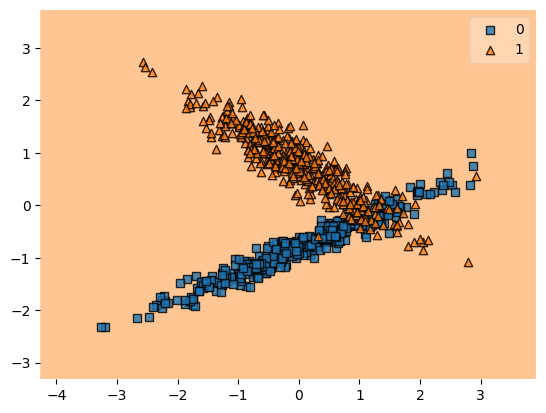

In [ ]:
plot_decision_regions(X_train , y_train , clf = model)

### **Zero Weight Initialization Observation**

* **The Core Problem (Symmetry):**
  When all weights are initialized to $0$, every neuron in a hidden layer computes the exact same output during the forward pass and receives the exact same gradient during backpropagation ($w_{i} \leftarrow w_{i} - \eta \frac{\partial L}{\partial w}$).
  Because all neurons update identically, **symmetry is never broken**. A hidden layer with 100 neurons behaves mathematically as if it has only **1 neuron**, destroying the capacity of a deep network.

* **Tanh Activation:**
  * **Forward Pass:** $z = Wx + b = 0 \implies \tanh(0) = 0$.
  * **Gradients:** Gradients for all neurons in a layer are non-zero but **100% identical**.
  * **Result:** Weights update, but every single neuron inside a layer keeps the exact same weight values as every other neuron. The network acts like a single-neuron model and fails to learn complex patterns.

* **ReLU Activation:**
  * **Forward Pass:** $z = Wx + b = 0 \implies \text{ReLU}(0) = 0$.
  * **Gradients:** Since $z = 0$, the derivative of ReLU at $0$ is $0$ (or subgradient $0$).
  * **Result:** Gradients vanish completely ($\frac{\partial L}{\partial W} = 0$). Weights do not update at all; the model stays dead/stuck at zero indefinitely.

* **Takeaway:**
  Zero initialization fails for both activation functions. Networks **must** use random initializations (e.g., **Xavier/Glorot** for Tanh, **He/Kaiming** for ReLU) to break symmetry across hidden neurons.

* **Non-Zero Constant Initialization (e.g., $W = c$, where $c \neq 0$):**
  Setting all weights to the exact same non-zero constant (e.g., $W = 0.5$ or $W = 1.0$) causes the exact same **Symmetry Problem** as zero initialization.
  
  Even though outputs and gradients may be non-zero (avoiding dead ReLU nodes at step 0), every neuron in a hidden layer receives identical inputs, computes identical activations, and receives identical gradient updates. Because no individual neuron has a distinct weight vector, symmetry is never broken, and all neurons continue to update identically forever—reducing the layer to a single effective neuron regardless of activation function ($\text{Sigmoid}$, $\text{Tanh}$, or $\text{ReLU}$).